In [1]:
# Cell 1: import library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns
from pathlib import Path

import json, warnings, time

In [5]:
# Cell 2: load dataset and setup
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)

bm = json.loads(Path("../data/processed/features_blocks_meta.json").read_text())
H, LAST_DAY = bm["H"], bm["LAST_DAY"]
TEST_START = LAST_DAY - H + 1

base = pd.read_parquet("../data/processed/features.parquet", columns=["d_num", "item_id", "cat_id", "sales"])
base["sales"] = base["sales"].astype("float32")
Y = base.pivot(index="item_id", columns="d_num", values="sales").reindex(columns=range(1, LAST_DAY + 1))
Y_np = Y.to_numpy()
cat_arr = (base.drop_duplicates("item_id").set_index("item_id")["cat_id"]
           .reindex(Y.index).astype(str).to_numpy())

rows = []
for i in(1, 2, 3):
    ve = TEST_START - 1 - (3 - i) * H
    vs = ve - H + 1
    rows.append({"fold": i, "train_end": vs - 1, "val_start": vs, "val_end": ve})

folds = pd.DataFrame(rows)
Yv = {int(f["fold"]): Y_np[:, int(f["val_start"]) - 1: int(f["val_end"])] for _, f in folds.iterrows()}

# Saved quantile predictions (sorted)
QUANTILES = [0.1, 0.5, 0.9]
PQ = {}
for a in QUANTILES:
    z = np.load(Path(f"../data/processed/pred_q{int(a * 100)}_sorted.npz"))
    PQ[a] = {int(k.replace("fold", "")): z[k] for k in z.files}
for a in QUANTILES:
    for fo in Yv:
        assert PQ[a][fo].shape == Yv[fo].shape, "shape differs"
        assert (np.isnan(PQ[a][fo]) == np.isnan(Yv[fo])).all(), "NaN pattern differs"


# Baselines
def moving_average(Y_train, h=H, w = 28):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=RuntimeWarning)
        ma = np.nanmean(Y_train[:, -w:], axis=1)
    return np.repeat(np.nan_to_num(ma, nan=0.0)[:, None], h, axis=1)

def moving_median(Y_train, h=H, w=28):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=RuntimeWarning)
        md = np.nanmedian(Y_train[:, -w:], axis=1)
    return np.repeat(np.nan_to_num(md, nan=0.0)[:, None], h, axis=1)

def emp_q(Y_train, a, h=H, w=28):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=RuntimeWarning)
        q = np.nanquantile(Y_train[:, -w:], a, axis=1)
    return np.repeat(np.nan_to_num(q, nan=0.0)[:, None], h, axis=1)

def by_fold(fn):
    return {int(f["fold"]): fn(Y_np[:, : int(f["train_end"])]) for _, f in folds.iterrows()}

MA, MED, EMP90 = by_fold(moving_average), by_fold(moving_median), by_fold(lambda Yt: emp_q(Yt, 0.9))

# checks
act = sum(np.nansum(Yv[fo]) for fo in Yv)

print("total actual units in the 3 windows:", int(act))
for name, Pd in (("LightGBM q0.1", PQ[0.1]), ("LightGBM q0.5", PQ[0.5]), ("LightGBM q0.9", PQ[0.9]),
                 ("empirical 28d q0.9", EMP90)):
    tot = sum(np.nansum(np.where(np.isnan(Yv[fo]), np.nan, Pd[fo])) for fo in Yv)
    print(f"{name}: total predicted / total actual = {tot / act:.3f}")
display(folds)

total actual units in the 3 windows: 376059
LightGBM q0.1: total predicted / total actual = 0.064
LightGBM q0.5: total predicted / total actual = 0.715
LightGBM q0.9: total predicted / total actual = 2.259
empirical 28d q0.9: total predicted / total actual = 2.050


,fold,train_end,val_start,val_end
0,1,1829,1830,1857
1,2,1857,1858,1885
2,3,1885,1886,1913


In [9]:
# Cell 3:simulation function, with tests

def pooled(P, rounding=None):
    Ss, Ds = [], []
    for fo in Yv:
        D, S = Yv[fo], P[fo]
        m = ~np.isnan(D)
        s = S[m].astype("float64")
        if rounding == "round":
            s = np.floor(s + 0.5)
        assert not np.isnan(s).any(), "stock level missing where demand exists"
        Ss.append(s)
        Ds.append(D[m].astype("float64"))
    return np.concatenate(Ss), np.concatenate(Ds)

def summarize(S, D):
    short = np.maximum(D - S, 0)
    over = np.maximum(S - D, 0)
    sales_days = D > 0
    return {"fill rate": 1 - short.sum() / D.sum(),
    "stockout units (% of demand)": 100 * short.sum() / D.sum(),
    "short on sales days (%)": 100 * np.mean((D > S)[sales_days]),
    "overstock units (% of demand)": 100 * over.sum() / D.sum(),
    "stock / demand": S.sum() / D.sum()}

# tests on tiny arrays
D = np.array([2., 0., 3.])
print("stock = demand :", {k: round(v, 3) for k, v in summarize(D.copy(), D).items()})
print("stock = 0      :", {k: round(v, 3) for k, v in summarize(np.zeros(3), D).items()})
print("mixed          :", {k: round(v, 3) for k, v in summarize(np.array([1., 1., 3.]), D).items()})

S_t = np.array([[5., 1.]]); D_t = np.array([[np.nan, 2.]])
m = ~np.isnan(D_t)
print("NaN demand ignored:", {k: round(v, 3) for k, v in summarize(S_t[m], D_t[m]).items()})

stock = demand : {'fill rate': np.float64(1.0), 'stockout units (% of demand)': np.float64(0.0), 'short on sales days (%)': np.float64(0.0), 'overstock units (% of demand)': np.float64(0.0), 'stock / demand': np.float64(1.0)}
stock = 0      : {'fill rate': np.float64(0.0), 'stockout units (% of demand)': np.float64(100.0), 'short on sales days (%)': np.float64(100.0), 'overstock units (% of demand)': np.float64(0.0), 'stock / demand': np.float64(0.0)}
mixed          : {'fill rate': np.float64(0.8), 'stockout units (% of demand)': np.float64(20.0), 'short on sales days (%)': np.float64(50.0), 'overstock units (% of demand)': np.float64(20.0), 'stock / demand': np.float64(1.0)}
NaN demand ignored: {'fill rate': np.float64(0.5), 'stockout units (% of demand)': np.float64(50.0), 'short on sales days (%)': np.float64(100.0), 'overstock units (% of demand)': np.float64(0.0), 'stock / demand': np.float64(0.5)}


In [10]:
# Cell 4: Compare the five stocking policies
policies = {"moving average (mean)": MA, "moving median": MED,
            "LightGBM P50": PQ[0.5], "LightGBM P90": PQ[0.9],
            "empirical P90 (28d)": EMP90}

for label, rounding in (("fractional stock (as forecast)", None), ("stock rounded to whole units", "round")):
    out = {}
    for name, P in policies.items():
        S, D = pooled(P, rounding)
        out[name] = summarize(S, D)
    print(f"\n=== {label} ===")
    display(pd.DataFrame(out).T.round(3))


=== fractional stock (as forecast) ===


,fill rate,stockout units (% of demand),short on sales days (%),overstock units (% of demand),stock / demand
moving average (mean),0.613,38.721,70.747,36.107,0.974
moving median,0.514,48.562,68.450,21.205,0.726
LightGBM P50,0.520,48.025,80.257,19.508,0.715
LightGBM P90,0.906,9.408,21.495,135.351,2.259
empirical P90 (28d),0.864,13.636,20.719,118.647,2.050



=== stock rounded to whole units ===


,fill rate,stockout units (% of demand),short on sales days (%),overstock units (% of demand),stock / demand
moving average (mean),0.619,38.128,52.793,34.623,0.965
moving median,0.529,47.053,64.593,22.842,0.758
LightGBM P50,0.518,48.210,69.027,18.800,0.706
LightGBM P90,0.907,9.275,13.472,134.625,2.254
empirical P90 (28d),0.858,14.160,20.275,114.679,2.005


check, LightGBM P90 rounded: fill rate 0.907 | stock/demand 2.254


,k,fill rate,stockout units (% of demand),short on sales days (%),overstock units (% of demand),stock / demand
moving average (mean),2.333,0.870,12.986,20.348,139.118,2.261
moving median,3.125,0.772,22.767,37.773,148.675,2.259
LightGBM P50,3.167,0.802,19.845,36.087,145.196,2.254
LightGBM P90,1.000,0.907,9.275,13.472,134.625,2.254
empirical P90 (28d),NaN,0.883,11.674,17.278,138.215,2.265


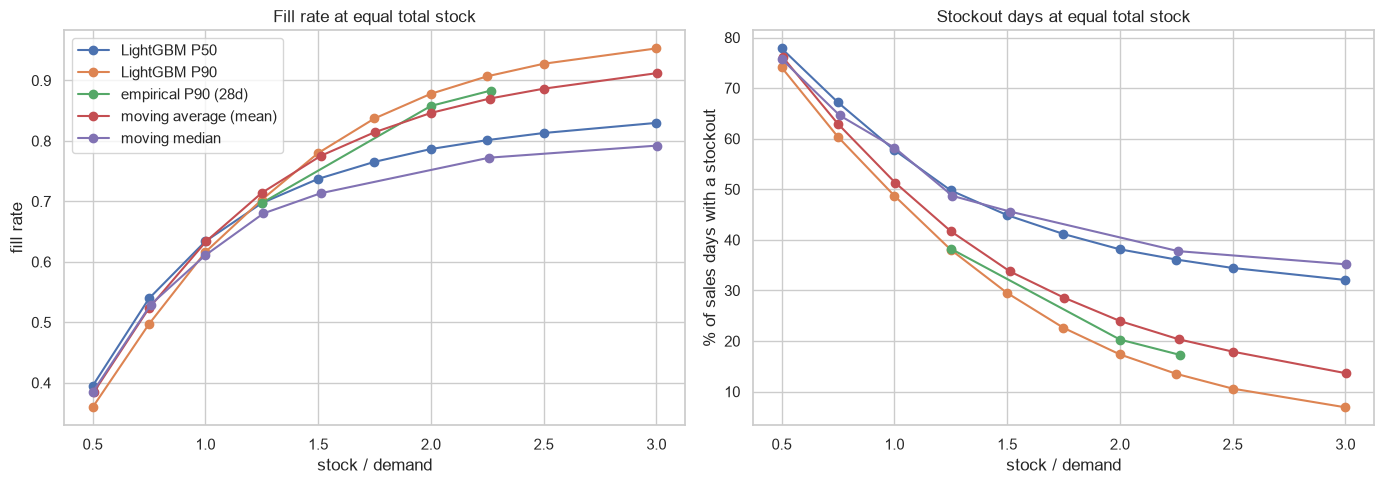

In [14]:
# Cell 5: Equal-inventory test and trade-off curve
D_all = np.concatenate([Yv[fo][~np.isnan(Yv[fo])] for fo in Yv]).astype("float64")

def flat_stock(P):
    return np.concatenate([P[fo][~np.isnan(Yv[fo])] for fo in Yv]).astype("float64")

FLAT = {name: flat_stock(P) for name, P in policies.items()}

def stock_k(p, k):
    return np.floor(k * p + 0.5)

def scale_to(p, target):
    lo, hi = 0.0, 1000.0
    for _ in range(60):
        mid = (lo + hi) / 2
        if stock_k(p, mid).sum() / D_all.sum() < target:
            lo = mid
        else:
            hi = mid
    return hi

# check: flat arrays reproduce the table above
chk = summarize(stock_k(FLAT["LightGBM P90"], 1.0), D_all)
print("check, LightGBM P90 rounded: fill rate", round(chk["fill rate"], 3),
      "| stock/demand", round(chk["stock / demand"], 3))              # expect 0.907 | 2.254

TARGET = chk["stock / demand"]

# equal-inventory table
rows = {}
for name, p in FLAT.items():
    k = scale_to(p, TARGET)
    s = stock_k(p, k)
    res = summarize(s, D_all)
    reached = abs(res["stock / demand"] - TARGET) < 0.01
    rows[name] = {"k": k if reached else np.nan, **res}
display(pd.DataFrame(rows).T.round(3))

# trade-off curve
targets = [0.5, 0.75, 1.0, 1.25, 1.5, 1.75, 2.0, 2.25, 2.5, 3.0]
curve = []
for name, p in FLAT.items():
    for t in targets:
        k = scale_to(p, t)
        res = summarize(stock_k(p, k), D_all)
        if abs(res["stock / demand"] - t) < 0.02:
            curve.append({"policy": name, "target": t, **res})
curve = pd.DataFrame(curve)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for name, g in curve.groupby("policy"):
    ax[0].plot(g["stock / demand"], g["fill rate"], marker="o", label=name)
    ax[1].plot(g["stock / demand"], g["short on sales days (%)"], marker="o", label=name)
ax[0].set_xlabel("stock / demand"); ax[0].set_ylabel("fill rate")
ax[0].set_title("Fill rate at equal total stock")
ax[1].set_xlabel("stock / demand"); ax[1].set_ylabel("% of sales days with a stockout")
ax[1].set_title("Stockout days at equal total stock")
ax[0].legend()
plt.tight_layout()
plt.show()

In [15]:
# Cell 6: Who benefits? By category and by item volume
meta_parts = []
for _, f in folds.iterrows():
    fo, te = int(f["fold"]), int(f["train_end"])
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=RuntimeWarning)
        vol28 = np.nanmean(Y_np[:, te - 28: te], axis=1)
    ii, dd = np.where(~np.isnan(Yv[fo]))
    meta_parts.append(pd.DataFrame({"cat": cat_arr[ii], "vol": np.nan_to_num(vol28[ii], nan=-1.0)}))
meta = pd.concat(meta_parts, ignore_index=True)
assert len(meta) == len(D_all), "metadata rows differ from demand rows"
meta["vol_bucket"] = pd.cut(meta["vol"], bins=[-1.5, -0.5, 0.1, 0.5, 1, 2, 5, 1e9],
                            labels=["no history", "<0.1", "0.1-0.5", "0.5-1", "1-2", "2-5", ">5"])

k_ma = rows["moving average (mean)"]["k"]
S_pol = {"LightGBM P90": stock_k(FLAT["LightGBM P90"], 1.0),
         "moving average x k": stock_k(FLAT["moving average (mean)"], k_ma),
         "empirical P90": stock_k(FLAT["empirical P90 (28d)"], 1.0)}

def group_table(by):
    out = []
    for g, idx in meta.groupby(by, observed=True).groups.items():
        idx = np.asarray(idx)
        if D_all[idx].sum() == 0:
            continue
        for name, S in S_pol.items():
            r = summarize(S[idx], D_all[idx])
            out.append({by: g, "policy": name, "fill rate": r["fill rate"],
                        "short days (%)": r["short on sales days (%)"], "stock / demand": r["stock / demand"]})
    t = pd.DataFrame(out)
    return t.pivot(index=by, columns="policy", values=["fill rate", "short days (%)", "stock / demand"])

for by in ("cat", "vol_bucket"):
    print(f"\nby {by}:")
    display(group_table(by).round(3))



by cat:


fill rate                                  short days (%)  \
policy    LightGBM P90 empirical P90 moving average x k   LightGBM P90   
cat                                                                      
FOODS            0.917         0.869              0.888         12.888   
HOBBIES          0.855         0.803              0.785         15.384   
HOUSEHOLD        0.904         0.855              0.861         13.670   

                                           stock / demand                \
policy    empirical P90 moving average x k   LightGBM P90 empirical P90   
cat                                                                       
FOODS            19.283             17.933          2.135         1.913   
HOBBIES          23.173             27.277          2.728         2.367   
HOUSEHOLD        20.772             21.620          2.355         2.089   

                              
policy    moving average x k  
cat                           
FOODS                  2.251  
HOBBIES                2.273  
HOUSEHOLD              2.287


by vol_bucket:


fill rate                                  short days (%)  \
policy     LightGBM P90 empirical P90 moving average x k   LightGBM P90   
vol_bucket                                                                
0.1-0.5           0.787         0.650              0.569         20.780   
0.5-1             0.869         0.809              0.759         12.888   
1-2               0.908         0.877              0.888         10.613   
2-5               0.931         0.905              0.936          9.247   
<0.1              0.558         0.000              0.000         47.248   
>5                0.951         0.935              0.972          9.183   
no history        1.000         0.000              0.000          0.000   

                                            stock / demand                \
policy     empirical P90 moving average x k   LightGBM P90 empirical P90   
vol_bucket                                                                 
0.1-0.5           33.521             43.049          3.419         2.479   
0.5-1             18.594             23.634          2.795         2.431   
1-2               14.104             12.093          2.443         2.274   
2-5               11.919              6.935          2.124         2.019   
<0.1             100.000            100.000          3.103         0.000   
>5                11.628              3.994          1.794         1.783   
no history       100.000            100.000          5.900         0.000   

                               
policy     moving average x k  
vol_bucket                     
0.1-0.5                 2.002  
0.5-1                   2.098  
1-2                     2.364  
2-5                     2.377  
<0.1                    0.000  
>5                      2.397  
no history              0.000

In [16]:
# Cell 7: equal stock inside each volume group
vb = meta["vol_bucket"].astype(str).to_numpy()
S_lgb = S_pol["LightGBM P90"]
S_ma_all = S_lgb.copy()
out6 = []
for g in meta["vol_bucket"].cat.categories:
    idx = np.where(vb == g)[0]
    if len(idx) == 0 or D_all[idx].sum() == 0:
        continue
    target = S_lgb[idx].sum() / D_all[idx].sum()
    p = FLAT["moving average (mean)"][idx]
    lo, hi = 0.0, 1000.0
    for _ in range(60):
        mid = (lo + hi) / 2
        if np.floor(mid * p + 0.5).sum() / D_all[idx].sum() < target:
            lo = mid
        else:
            hi = mid
    s_ma = np.floor(hi * p + 0.5)
    S_ma_all[idx] = s_ma
    r_l, r_m = summarize(S_lgb[idx], D_all[idx]), summarize(s_ma, D_all[idx])
    out6.append({"volume": g, "demand units": int(D_all[idx].sum()),
                 "target stock/demand": target, "reached": abs(r_m["stock / demand"] - target) < 0.02,
                 "fill LGB P90": r_l["fill rate"], "fill moving avg": r_m["fill rate"],
                 "short days LGB (%)": r_l["short on sales days (%)"],
                 "short days MA (%)": r_m["short on sales days (%)"]})
display(pd.DataFrame(out6).round(3))

r1, r2 = summarize(S_lgb, D_all), summarize(S_ma_all, D_all)
print("\noverall, equal stock in every group:")
print("LightGBM P90    : fill", round(r1["fill rate"], 3), "| stock/demand", round(r1["stock / demand"], 3))
print("moving avg (grp): fill", round(r2["fill rate"], 3), "| stock/demand", round(r2["stock / demand"], 3))

,volume,demand units,target stock/demand,reached,fill LGB P90,fill moving avg,short days LGB (%),short days MA (%)
0,no history,10,5.900,False,1.000,0.000,0.000,100.000
1,<0.1,9987,3.103,False,0.558,0.157,47.248,69.785
2,0.1-0.5,25289,3.419,False,0.787,0.780,20.780,21.135
3,0.5-1,43301,2.795,True,0.869,0.855,12.888,13.308
4,1-2,68854,2.443,True,0.908,0.898,10.613,10.885
5,2-5,92753,2.124,True,0.931,0.915,9.247,9.774
6,>5,135865,1.794,True,0.951,0.935,9.183,10.926



overall, equal stock in every group:
LightGBM P90    : fill 0.907 | stock/demand 2.254
moving avg (grp): fill 0.883 | stock/demand 2.283


## Summary of Notebook 09: inventory simulation

**Rules (assumptions)**
- Stock for each item and day set from the forecast at the cutoff; demand = observed sale of that day; days are independent; unsold units are wasted; no prices or costs; stock rounded to whole units
- Three validation windows pooled (376,059 units of demand); final test window not used
- Observed sales can understate real demand on stockout days, so true stockouts are probably higher

**Policies (rounded stock)**

| Policy | Fill rate | Stockout units (% of demand) | Short on sales days | Overstock (% of demand) | Stock / demand |
|---|---|---|---|---|---|
| moving average (mean) | 0.619 | 38.1 | 52.8% | 34.6 | 0.965 |
| moving median | 0.529 | 47.1 | 64.6% | 22.8 | 0.758 |
| LightGBM P50 | 0.518 | 48.2 | 69.0% | 18.8 | 0.706 |
| **LightGBM P90** | **0.907** | **9.3** | **13.5%** | 134.6 | 2.254 |
| empirical P90 (28d) | 0.858 | 14.2 | 20.3% | 114.7 | 2.005 |

**Equal total stock (about 2.25 x demand)**
- LightGBM P90: fill 0.907, stockout units 9.3%, short days 13.5%
- empirical P90: 0.883 / 11.7% / 17.3% (0.5% more stock)
- moving average x 2.33: 0.870 / 13.0% / 20.3%
- LightGBM P50 x 3.17: 0.802 / 19.8% / 36.1%; moving median x 3.13: 0.772 / 22.8% / 37.8%
- P90 curve starts below the others at low stock (stock/demand 0.5-0.75) and leads from about 1.5 up

**By group**
- Category fill rate (LGB P90 / moving average scaled): FOODS 0.917 / 0.888 (with 5% less stock), HOUSEHOLD 0.904 / 0.861, HOBBIES 0.855 / 0.785 (20% more stock)
- P90 reallocates stock: 25% less than the scaled moving average for items over 5 units/day, 33-71% more for items under 1 unit/day
- Equal stock within volume groups of 0.5+ units/day: fill +1.0 to +1.6 points and 0.3 to 1.7 points fewer short days; overall with equalised allocation 0.907 vs 0.883 (moving average held 1.3% more stock)
- About 55% of the overall fill-rate gain comes from groups with matched stock, about 45% from items under 0.1 units/day that the moving average stocks at zero (stock not matched there)

**Limits (for the README)**
- Days independent, no carry-over, no costs; the right balance between waste and lost sales depends on item type and is not in the data
- Overstock is large (about 135% of demand at P90)
- Groups 0.1-0.5, <0.1 and no history could not be matched exactly by the scaled moving average (whole-unit rounding)
- Spring windows only; no holiday fold